# 02 - Selecting the galaxy sample

**Goal:** choose the best galaxies for measuring the Faber-Jackson (FJ) relation, and keep a record of every galaxy we remove and why.

The FJ relation (Faber & Jackson 1976) was found for elliptical galaxies, which are supported by random stellar motions (velocity dispersion) rather than rotation. So our main sample is early-type galaxies (ellipticals and S0s). We also keep spirals as a comparison sample..

Every cut is applied one at a time, and each galaxy gets a `removed_by` label saying which cut removed it (or `kept`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs('../figures', exist_ok=True)

df = pd.read_csv('../data/processed/sami_merged.csv')
print('Starting sample (galaxies with SAMI kinematics data):', len(df))

Starting sample (galaxies with SAMI kinematics data): 3068


## 1. Morphology codes

The SAMI visual morphology `type` column uses these codes:

| type | meaning |
|---|---|
| 0 | Elliptical (E) |
| 0.5 | E/S0 |
| 1 | S0 (lenticular) |
| 1.5 | S0 / early spiral |
| 2 | Early spiral |
| 2.5 | Early/late spiral |
| 3 | Late spiral |
| 5 | Unknown (?) |
| -9 | Classifiers did not agree |

In [2]:
df['type'].value_counts().sort_index()

type
-9.0     134
 0.0     300
 0.5     261
 1.0     369
 1.5     359
 2.0     358
 2.5     247
 3.0    1026
 5.0      14
Name: count, dtype: int64

## 2. Apply the quality cuts one by one

Each cut is a True/False test. A galaxy that fails a test is labelled with that cut's name, and later cuts only look at galaxies that are still in the sample.

Some galaxies have SAMI kinematics but are not in either the GAMA or Cluster input catalogue (they were observed as extra "filler" targets), so they have no magnitude or mass from our tables and are removed.

SAMI DR3 already only reports sigma above 35 km/s (below this the dispersion is smaller than the instrument's resolution and can't be trusted), so we don't need to apply that cut ourselves. We check it below.

In [3]:
print('Smallest sigma_re in the data:', round(df['sigma_re'].min(), 1), 'km/s')

Smallest sigma_re in the data: 35.0 km/s


In [4]:
frac_err = df['sigma_re_err'] / df['sigma_re']

cuts = [
    ('missing or invalid sigma', df['sigma_re'].notna() & (df['sigma_re'] > 0)),
    ('missing or invalid sigma error', df['sigma_re_err'].notna() & (df['sigma_re_err'] > 0)),
    ('no morphology',          df['type'].notna() & (df['type'] >= 0) & (df['type'] != 5)),
    ('not in input catalogue', df['environment'].notna()),
    ('bad photometry flag',    df['bad_class'] == 0),
    ('not a cluster member',   (df['environment'] == 'GAMA') | (df['is_mem'] == 1)),
    ('missing M_r or mass',    df['m_r'].notna() & df['mstar'].notna()),
    ('sigma error >= 10%', frac_err < 0.10),
]

df['removed_by'] = 'kept'
cut_flow = [('start: all SAMI kinematics', len(df))]

for name, passes in cuts:
    still_in = df['removed_by'] == 'kept'
    df.loc[still_in & ~passes, 'removed_by'] = name
    n_left = (df['removed_by'] == 'kept').sum()
    cut_flow.append(('remove ' + name, n_left))
    print(f'{name:25s} -> {n_left} galaxies left')

missing or invalid sigma  -> 2251 galaxies left
missing or invalid sigma error -> 2251 galaxies left
no morphology             -> 2149 galaxies left
not in input catalogue    -> 2148 galaxies left
bad photometry flag       -> 2135 galaxies left
not a cluster member      -> 2104 galaxies left
missing M_r or mass       -> 2103 galaxies left
sigma error >= 10%        -> 1877 galaxies left


## 3. Split into early types and spirals

Galaxies that pass every cut are split by morphology:
- Early types (main FJ sample): type 0, 0.5 or 1 (E, E/S0, S0)
- Spirals (comparison sample): type 1.5 to 3

The S0/early-spiral class (1.5) goes in the spiral group because those galaxies already show some disk/spiral structure, and we want the early-type sample to be clean.

In [5]:
good = df[df['removed_by'] == 'kept']

early = good[
    (good['type'] == 0) |
    (good['type'] == 0.5) |
    (good['type'] == 1)
].copy()
spirals = good[good['type'] > 1].copy()

labels = {0: 'E', 0.5: 'E/S0', 1: 'S0'}
early['morph'] = early['type'].map(labels)

print('Early types (E, E/S0, S0):', len(early))
print(early['morph'].value_counts())
print()
print('Spirals (comparison):', len(spirals))
print()
print('Early types by environment:')
print(early['environment'].value_counts())

Early types (E, E/S0, S0): 768
morph
S0      328
E       225
E/S0    215
Name: count, dtype: int64

Spirals (comparison): 1109

Early types by environment:
environment
GAMA       414
Cluster    354
Name: count, dtype: int64


## 4. Cut-flow figure

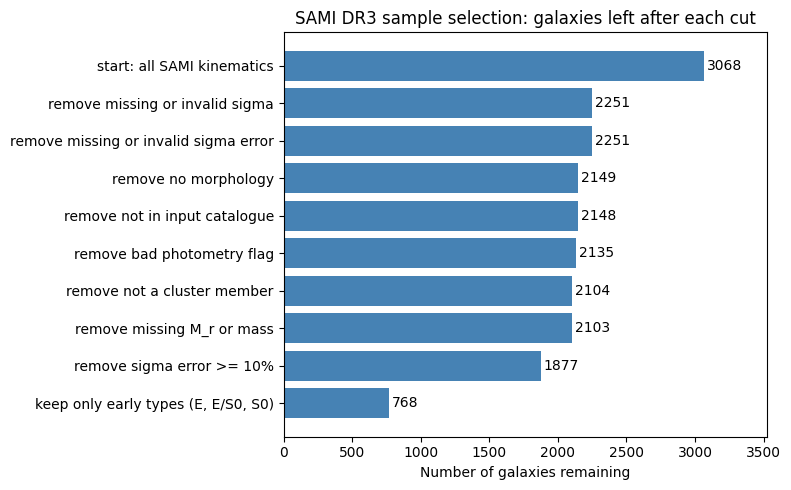

In [6]:
names = [c[0] for c in cut_flow] + ['keep only early types (E, E/S0, S0)']
counts = [c[1] for c in cut_flow] + [len(early)]

plt.figure(figsize=(8, 5))
plt.barh(names, counts, color='steelblue')
for i, n in enumerate(counts):
    plt.text(n + 20, i, str(n), va='center')
plt.gca().invert_yaxis()
plt.xlabel('Number of galaxies remaining')
plt.title('SAMI DR3 sample selection: galaxies left after each cut')
plt.xlim(0, max(counts) * 1.15)
plt.tight_layout()
plt.savefig('../figures/01_cut_flow.png', dpi=150)
plt.show()

## 5. Look at the properties of the selected samples

Histograms of the three quantities we will use in the FJ relation, comparing early types with spirals.

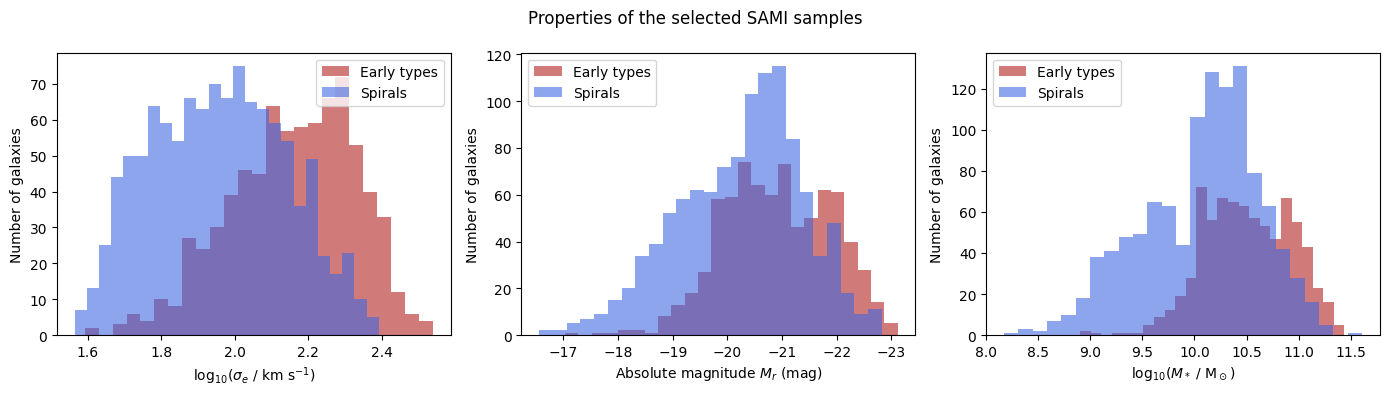

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(np.log10(early['sigma_re']), bins=25, alpha=0.6, label='Early types', color='firebrick')
axes[0].hist(np.log10(spirals['sigma_re']), bins=25, alpha=0.6, label='Spirals', color='royalblue')
axes[0].set_xlabel(r'log$_{10}$($\sigma_e$ / km s$^{-1}$)')

axes[1].hist(early['m_r'], bins=25, alpha=0.6, label='Early types', color='firebrick')
axes[1].hist(spirals['m_r'], bins=25, alpha=0.6, label='Spirals', color='royalblue')
axes[1].set_xlabel(r'Absolute magnitude $M_r$ (mag)')
axes[1].invert_xaxis()   

axes[2].hist(early['mstar'], bins=25, alpha=0.6, label='Early types', color='firebrick')
axes[2].hist(spirals['mstar'], bins=25, alpha=0.6, label='Spirals', color='royalblue')
axes[2].set_xlabel(r'log$_{10}$($M_*$ / M$_\odot$)')

for ax in axes:
    ax.set_ylabel('Number of galaxies')
    ax.legend()

fig.suptitle('Properties of the selected SAMI samples')
plt.tight_layout()
plt.savefig('../figures/02_sample_histograms.png', dpi=150)
plt.show()

## 6. First look at the Faber-Jackson relation

A quick plot to check the selected early types show the expected trend: brighter galaxies have larger velocity dispersions.

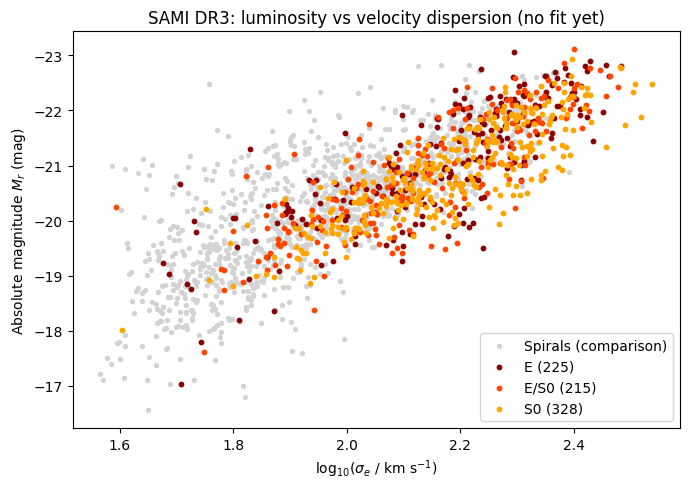

In [8]:
plt.figure(figsize=(7, 5))
plt.scatter(np.log10(spirals['sigma_re']), spirals['m_r'], s=8, color='lightgrey', label='Spirals (comparison)')
for m, colour in [('E', 'darkred'), ('E/S0', 'orangered'), ('S0', 'orange')]:
    sub = early[early['morph'] == m]
    plt.scatter(np.log10(sub['sigma_re']), sub['m_r'], s=10, color=colour, label=f'{m} ({len(sub)})')

plt.gca().invert_yaxis()  
plt.xlabel(r'log$_{10}$($\sigma_e$ / km s$^{-1}$)')
plt.ylabel(r'Absolute magnitude $M_r$ (mag)')
plt.title('SAMI DR3: luminosity vs velocity dispersion (no fit yet)')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/03_fj_first_look.png', dpi=150)
plt.show()

## 7. Save the samples and the selection log

- `selection_log.csv` - every galaxy, with the reason it was removed (or `kept`)
- `sample_early_types.csv` - the main Faber-Jackson sample
- `sample_spirals.csv` - the comparison sample

In [9]:
df[['catid', 'environment', 'type', 'sigma_re', 'sigma_re_err', 'm_r', 'mstar', 'bad_class', 'is_mem', 'removed_by']] \
    .to_csv('../data/processed/selection_log.csv', index=False)
early.to_csv('../data/processed/sample_early_types.csv', index=False)
spirals.to_csv('../data/processed/sample_spirals.csv', index=False)

print('Why galaxies were removed:')
print(df['removed_by'].value_counts())

Why galaxies were removed:
removed_by
kept                        1877
missing or invalid sigma     817
sigma error >= 10%           226
no morphology                102
not a cluster member          31
bad photometry flag           13
not in input catalogue         1
missing M_r or mass            1
Name: count, dtype: int64
